In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244081127

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp_env
[学号]       20244081127
[机器指纹] 129b330c7033e382
[RUN_ID]   20244081127-129b330c7033e382


## 实验1：Numpy数组、数据类型与索引

In [2]:
# ========== 任务1 数组类型和维度 ==========
# 整数数组
arr_int = np.array([1,2,3,4])
# 浮点数数组
arr_float = np.array([1.1,2.2,3.3,4.4])
# 布尔数组
arr_bool = np.array([True,False,True,False])

print("整数数组：")
print(f"dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}")
print("浮点数组：")
print(f"dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}")
print("布尔数组：")
print(f"dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")

整数数组：
dtype:int64, shape:(4,), ndim:1
浮点数组：
dtype:float64, shape:(4,), ndim:1
布尔数组：
dtype:bool, shape:(4,), ndim:1


- NumPy ndarray：整个数组所有元素必须是同一种数据类型，底层连续内存存储，计算速度快。  
- Python list：列表元素类型可以不一样，内存分散，适合存放不同类型对象，批量数值运算效率低。

In [3]:
# ========== 任务2 数组reshape()方法 ==========
arr_1d = np.arange(12)
print("原始一维数组：")
print(arr_1d)

arr_34 = arr_1d.reshape(3,4)
print("\nreshape(3,4):")
print(arr_34)

arr_232 = arr_1d.reshape(2,3,2)
print("\nreshape(2,3,2):")
print(arr_232)

原始一维数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


**reshape() 修改形状时元素总数须满足的条件**：  
新形状所有维度相乘，必须等于数组总元素个数，这里 12 = 3×4 =2×3×2，否则报错。

In [4]:
# ========== 任务3 数组切片 ==========
arr_34 = np.arange(12).reshape(3,4)
print("原数组：\n",arr_34)

# 取第2行
row2 = arr_34[1,:]
print("\n取第2行：",row2, "，shape=",row2.shape)

# 取第1至第3列
col1_3 = arr_34[:,0:3]
print("\n第1~3列：\n",col1_3, "，shape=",col1_3.shape)

# 大于6的元素
big6 = arr_34[arr_34>6]
print("\n大于6的元素：",big6, "，shape=",big6.shape)

原数组：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行： [4 5 6 7] ，shape= (4,)

第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] ，shape= (3, 3)

大于6的元素： [ 7  8  9 10 11] ，shape= (5,)


In [5]:
# ========== 任务4 布尔运算符 ==========
arr = np.arange(10)
print("原始数组",arr)

# 小于2 或 大于7
res_or = arr[(arr < 2) | (arr >7)]
# res_or = arr[np.logical_or(arr<2, arr>7)]
print("小于2或大于7：", res_or)

#大于3 且 小于7
res_and = arr[(arr>3) & (arr<7)]
# res_and = arr[np.logical_and(arr>3, arr<7)]
print("大于3且小于7：", res_and)

原始数组 [0 1 2 3 4 5 6 7 8 9]
小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


In [6]:
# ========== 任务5 矩阵运算 ==========
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("A=\n",A)
print("B=\n",B)

#逐元素乘法
ele1 = A * B
ele2 = np.multiply(A,B)
print("\n逐元素乘法 A*B：\n",ele1)
print("np.multiply(A,B):\n",ele2)

#矩阵乘法
mat1 = A @ B
mat2 = np.matmul(A,B)
print("\n矩阵乘法 A@B：\n",mat1)
print("np.matmul(A,B):\n",mat2)

A=
 [[1 2]
 [3 4]]
B=
 [[5 6]
 [7 8]]

逐元素乘法 A*B：
 [[ 5 12]
 [21 32]]
np.multiply(A,B):
 [[ 5 12]
 [21 32]]

矩阵乘法 A@B：
 [[19 22]
 [43 50]]
np.matmul(A,B):
 [[19 22]
 [43 50]]


**逐元素乘法与矩阵乘法的区别**：  
- `*` 和`np.multiply()`：逐元素相乘，对应位置元素相乘，只要求两个数组 shape 完全一样。  
- `@` 和`np.matmul()`：数学矩阵乘法，遵循矩阵乘法规则，要求前矩阵列数 = 后矩阵行数。

## 实验2：随机抽样、统计与缺失值

In [7]:
np.random.seed(27)  # 设置随机数种子

# ========== 任务1 正态随机样本生成与描述性统计 ==========
# 生成1000个，均值70，标准差10正态分布
scores = np.random.normal(loc=70, scale=10, size=1000)
# 限制0~100
scores = np.clip(scores, a_min=0, a_max=100)

print("样本数：", len(scores))
print("最小值：", np.min(scores))
print("最大值：", np.max(scores))
print("均值：", np.mean(scores))
print("标准差：", np.std(scores))
print("极差：", np.max(scores)-np.min(scores))

样本数： 1000
最小值： 36.584965508631306
最大值： 100.0
均值： 69.92189231042538
标准差： 10.266509130934823
极差： 63.415034491368694


In [8]:
# ========== 任务2 正态抽样 ==========
arr = np.arange(1,11)
print("原始数组：", arr)

# 不放回均匀抽样5个，每个元素等概率
sample_uniform = np.random.choice(arr, size=5, replace=False)
print("均匀不放回抽样：", sample_uniform)

# 按整数大小加权抽样，权重等于元素本身的值
weights = arr / np.sum(arr)
sample_weighted = np.random.choice(arr, size=5, replace=False, p=weights)
print("按整数大小加权不放回抽样：", sample_weighted)

原始数组： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [10  3  5  1  4]
按整数大小加权不放回抽样： [ 5  3  6 10  9]


- 均匀抽样：每个元素被抽中概率完全相同。  
- 加权抽样：传入`p`参数，数值大的元素被选中概率更高，总和必须 = 1。

In [9]:
# ========== 任务3 随机打乱数组 ==========
data = np.array([1,2,3,4,5,6,7,8])
print("原始数组：", data)

# 方式1：随机排列后，返回新数组，原数组不变
shuffle_new = np.random.permutation(data)
print("\npermutation得到新数组：", shuffle_new)
print("permutation之后原数组：", data)

# 方式2：原地打乱，直接修改原数组
data_copy = data.copy()
np.random.shuffle(data_copy)
print("\nshuffle原地打乱后的数组：", data_copy)
print("shuffle之后原数组副本：", data_copy)

原始数组： [1 2 3 4 5 6 7 8]

permutation得到新数组： [8 6 4 7 3 1 5 2]
permutation之后原数组： [1 2 3 4 5 6 7 8]

shuffle原地打乱后的数组： [1 3 4 5 7 2 6 8]
shuffle之后原数组副本： [1 3 4 5 7 2 6 8]


- `np.random.permutation()`：生成新数组，不改动原始数组。
- `np.random.shuffle()`：原地直接修改原数组，无返回值，原始数组顺序被改变。

In [10]:
# ========== 任务4 对比含缺失值与忽略缺失值的均值计算 ==========
# 沿用任务1的成绩数组，复制一份
scores_nan = scores.copy()
# 第10、20、30个成绩设为nan
scores_nan[[9,19,29]] = np.nan

mean_normal = np.mean(scores_nan)          #普通均值
mean_skip_nan = np.nanmean(scores_nan)     #忽略nan求均值
nan_count = np.sum(np.isnan(scores_nan))

print("普通mean均值（含nan）：", mean_normal)
print("忽略缺失值nanmean均值：", mean_skip_nan)
print("缺失值个数：", nan_count)

普通mean均值（含nan）： nan
忽略缺失值nanmean均值： 69.92355010636383
缺失值个数： 3


只要数组存在`np.nan`，普通`np.mean`结果直接返回`nan`，无法正常计算。  
`np.nanmean`会自动跳过所有`nan`，只用有效数值计算均值。

In [11]:
# ========== 任务5 构造序号-成绩二维表 ==========
# 构造表格变量，序号+成绩
idx = np.arange(len(scores_nan))
table = np.column_stack((idx, scores_nan))
print("表格（序号，模拟成绩），前10行：")
print(table[:10])

表格（序号，模拟成绩），前10行：
[[ 0.         82.85605415]
 [ 1.         66.96446623]
 [ 2.         76.19075662]
 [ 3.         73.95998549]
 [ 4.         72.23405648]
 [ 5.         69.45660583]
 [ 6.         68.20723674]
 [ 7.         72.42831973]
 [ 8.         78.21056548]
 [ 9.                 nan]]


## 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
np.random.seed(27)

# ========== 任务1 线性方程组求解 ==========
# 方程组：
# 3x + y = 9
# x + 2y = 8
A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
sol = scipy.linalg.solve(A, b)
x, y = sol
print(f"解：x={x}, y={y}")

# 代入验证
print("代入验证 3x+y =", 3*x + y)
print("代入验证 x+2y =", x + 2*y)

解：x=2.0, y=3.0
代入验证 3x+y = 9.0
代入验证 x+2y = 8.0


In [13]:
# ========== 任务2 根求解器 ==========
def f(x):
    return x**2 - 2

# 求正根，初猜2
res_pos = scipy.optimize.root(f, x0=2)
# 求负根，初猜-2
res_neg = scipy.optimize.root(f, x0=-2)

print("正根求解成功？", res_pos.success)
print("正根 =", res_pos.x, "函数值f(x)=", f(res_pos.x))
print("负根求解成功？", res_neg.success)
print("负根 =", res_neg.x, "函数值f(x)=", f(res_neg.x))

正根求解成功？ True
正根 = [1.41421356] 函数值f(x)= [8.8817842e-16]
负根求解成功？ True
负根 = [-1.41421356] 函数值f(x)= [8.8817842e-16]


得到函数值计算结果8.8817842e-16非常接近0。

In [14]:
# ========== 任务3 极值求解器 ==========
def f(x):
    return x**2 + x + 2

# 初值猜测 x0=0
res_min = scipy.optimize.minimize(f, x0=0)
print("极小点 x =", res_min.x[0])
print("极小函数值 f(x) =", res_min.fun)

# 解析解：导数2x+1=0 → x=-0.5
print("解析极小点 x = -0.5，解析极小值 =", (-0.5)**2 + (-0.5)+2)

极小点 x = -0.5000000064345924
极小函数值 f(x) = 1.75
解析极小点 x = -0.5，解析极小值 = 1.75


用`scipy.optimize.minimize()`求得的函数最小值与解析结果一致。

In [15]:
# ========== 任务4 独立样本t检验 ==========
# 生成两组样本
s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)

# 独立样本t检验
t_stat, p_value = scipy.stats.ttest_ind(s1, s2)
print("t统计量：", t_stat)
print("p值：", p_value)

alpha = 0.05
if p_value < alpha:
    print(f"p < {alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p ≥ {alpha}，不能拒绝原假设，无足够证据说明均值有差异")

t统计量： -6.886071094580087
p值： 7.422038225775642e-11
p < 0.05，拒绝原假设，两组均值存在显著差异


独立样本 t 检验，原假设：两组总体均值相等。  
显著性水平$alpha=0.05$：p 小于 0.05，认为两组均值有显著差异。

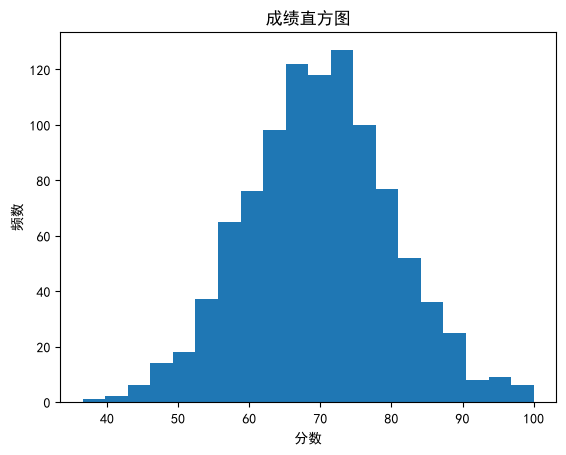

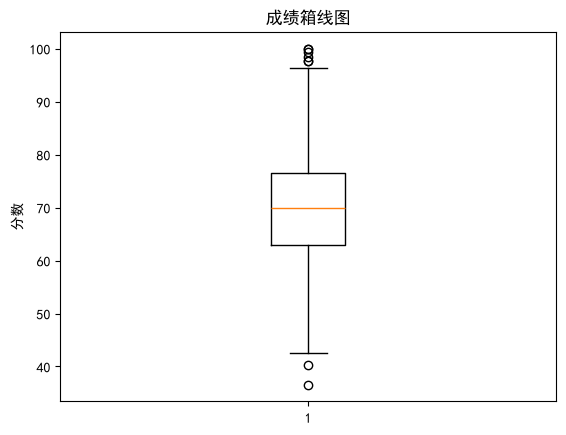

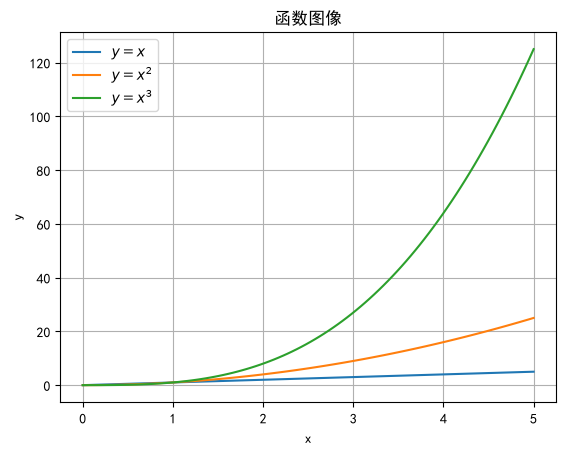

In [16]:
# ========== 任务5 Matplotlib绘图 ==========
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]   # 设置黑体，支持中文
plt.rcParams["axes.unicode_minus"] = False    # 解决负号显示成方框问题

# 1、实验2有效成绩直方图 + 箱线图
# 取出成绩那一列
score_col = table[:,1]
# 剔除nan，得到有效成绩
valid_scores = score_col[~np.isnan(score_col)]

# 直方图
plt.figure()
plt.hist(valid_scores, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")
plt.show()

# 箱线图
plt.figure()
plt.boxplot(valid_scores)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

# 2、函数 y=x, y=x², y=x³，0≤x≤5 折线图 
x = np.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3

plt.figure()
plt.plot(x,y1,label="$y=x$")
plt.plot(x,y2,label="$y=x^2$")
plt.plot(x,y3,label="$y=x^3$")
plt.title("函数图像")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [17]:
# ========== 任务1 数据处理 ==========
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records)
df = df.set_index("Name")

# 计算总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
# ========== 任务2 数据读取 ==========
# loc：按索引名字取Carol
print("loc读取Carol：")
print(df.loc["Carol"])

# iloc：按位置取Carol
print("\niloc读取Carol：")
print(df.iloc[2])

# 筛选平均分不低于80的学生
high_avg = df[df["Average"] >= 80]
print("\n平均分≥80的学生：")
print(high_avg)

loc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分≥80的学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
# ========== 任务3 列均值和行均值 ==========
# axis=0 列均值（每科的平均分）
col_mean = df[["Math","English","Python"]].mean(axis=0)
print("三科列均值(axis=0)：")
print(col_mean)

# axis=1 行均值（每个学生平均分，和Average列一致）
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("\n每个学生行均值(axis=1)：")
print(row_mean)

三科列均值(axis=0)：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1)：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
# ========== 任务4 按行求最高分、多列聚合统计、成绩排名 =========
# apply：每行求三科最高分
df["MaxScore"] = df[["Math","English","Python"]].apply(max, axis=1)
print("每人三科最高分：")
print(df["MaxScore"])

# agg：一次性得到每科 min, mean, max
agg_result = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\n每科 最小、均值、最大值：")
print(agg_result)

# rank：用Python成绩排名，高分名次靠前
df["Python_Rank"] = df["Python"].rank(ascending=False).astype(int)
print("\nPython成绩排名：")
print(df[["Python","Python_Rank"]])

每人三科最高分：
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: MaxScore, dtype: int64

每科 最小、均值、最大值：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Python成绩排名：
       Python  Python_Rank
Name                      
Alice      95            1
Bob        80            5
Carol      89            2
David      70            6
Eva        86            3
Frank      82            4


In [21]:
# ========== 任务5 分组统计 =========
# 按Group分组，统计每组人数、三科平均分
group_stat = df.groupby("Group").agg(
    count_student = ("Math", "count"),
    Math_mean = ("Math","mean"),
    English_mean = ("English","mean"),
    Python_mean = ("Python","mean")
)
print("分组统计：")
print(group_stat)

# transform，新增一列：该行学生所在组的Python平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加本组Python平均分后的df：")
print(df)

分组统计：
       count_student  Math_mean  English_mean  Python_mean
Group                                                     
A                  3  79.666667     83.333333    87.000000
B                  3  80.000000     78.333333    80.333333

增加本组Python平均分后的df：
      Group  Math  English  Python  Total    Average  MaxScore  Python_Rank  \
Name                                                                          
Alice     A    88       90      95    273  91.000000        95            1   
Bob       A    72       68      80    220  73.333333        80            5   
Carol     B    91       85      89    265  88.333333        91            2   
David     B    65       73      70    208  69.333333        73            6   
Eva       A    79       92      86    257  85.666667        92            3   
Frank     B    84       77      82    243  81.000000        84            4   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000

In [22]:
# ========== 任务6 分组筛选方法 =========
# filter：保留组内Python平均分不低于80的组
group_filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("Python组平均分不低于80的组及学生：")
print(group_filtered)

Python组平均分不低于80的组及学生：
      Group  Math  English  Python  Total    Average  MaxScore  Python_Rank  \
Name                                                                          
Alice     A    88       90      95    273  91.000000        95            1   
Bob       A    72       68      80    220  73.333333        80            5   
Carol     B    91       85      89    265  88.333333        91            2   
David     B    65       73      70    208  69.333333        73            6   
Eva       A    79       92      86    257  85.666667        92            3   
Frank     B    84       77      82    243  81.000000        84            4   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [23]:
# ========== 任务7 协方差和皮尔森相关系数矩阵 =========
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()

print("协方差矩阵：")
print(cov_matrix)
print("\n皮尔森相关系数矩阵：")
print(corr_matrix)

协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


以 Math 与 Python 为例：协方差为正，说明两门成绩同向变化，数学高分学生 Python 大多也偏高；  
相关系数大小代表线性相关强弱，越接近 1 线性正相关越强，接近 0 几乎无线性相关。